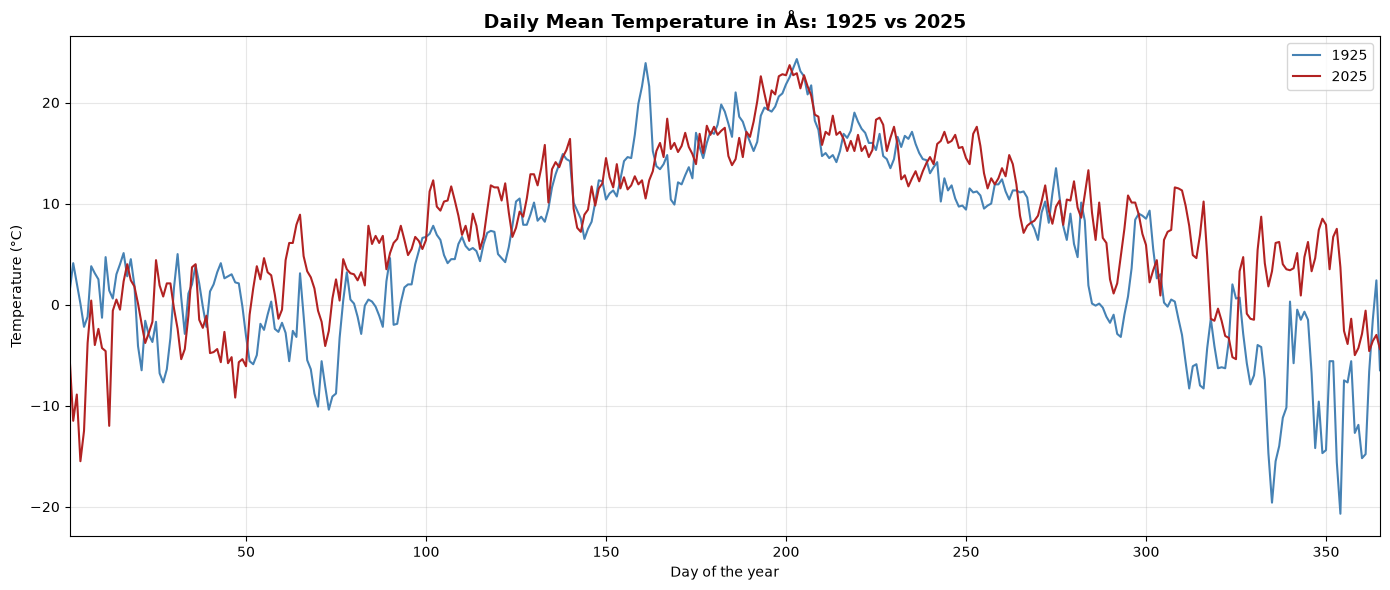


Temperature Summary: 1925 vs 2025
        1925 (°C)  2025 (°C)
mean         5.28       7.87
median       5.30       8.30
min        -20.70     -15.50
max         24.30      23.70


In [8]:

# INF201 - Deliverable 1
# Task 3: Historical Temperature Data

"""

FILL IN LATER

"""

import requests
import pandas as pd
import matplotlib.pyplot as plt

# Read the client ID from secrets.txt
with open("secrets.txt", "r") as f:
    client_id = f.read().strip()

endpoint = "https://frost.met.no/observations/v0.jsonld"


# Function to get temperature data for a chosen year
def get_temperature(year):

    # Set up the station, measurement type and date range
    parameters = {"sources": "SN17850", "elements": "mean(air_temperature P1D)", "referencetime": f"{year}-01-01/{year+1}-01-01"}

    # Request data from Frost using our client ID
    response = requests.get(endpoint, params=parameters, auth=(client_id, ""), timeout=30)

    rows = []

    # Go through all dates and temperature measurements
    for item in response.json()["data"]:
        for observation in item["observations"]:

            # Use PT0H, like in Task 1
            if observation["timeOffset"] == "PT0H":
                rows.append({
                    "date": item["referenceTime"],
                    "temperature": observation["value"]
                })

    # Turn the list into a DataFrame
    df = pd.DataFrame(rows, columns=["date", "temperature"])

    # Convert the dates into actual datetime values
    df["date"] = pd.to_datetime(df["date"], utc=True)

    # Only keep dates from the requested year
    df = df[df["date"].dt.year == year]

    return df.sort_values("date")


# Download temperature data for both years
temperature_1925 = get_temperature(1925)
temperature_2025 = get_temperature(2025)


# Get the day number to compare both years
temperature_1925["day"] = temperature_1925["date"].dt.dayofyear
temperature_2025["day"] = temperature_2025["date"].dt.dayofyear


# Create the plot
fig, ax = plt.subplots(figsize=(14, 6))

# Temperature from 1925
ax.plot(
    temperature_1925["day"],
    temperature_1925["temperature"],
    color="steelblue",
    linewidth=1.5,
    label="1925"
)

# Temperature from 2025
ax.plot(
    temperature_2025["day"],
    temperature_2025["temperature"],
    color="firebrick",
    linewidth=1.5,
    label="2025"
)

# Labels and title
ax.set_xlabel("Day of the year")
ax.set_ylabel("Temperature (°C)")
ax.set_title(
    "Daily Mean Temperature in Ås: 1925 vs 2025",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlim(1, 365)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# Create a summary table for both years
summary_table = pd.DataFrame({
    "1925 (°C)": [
        temperature_1925["temperature"].mean(),
        temperature_1925["temperature"].median(),
        temperature_1925["temperature"].min(),
        temperature_1925["temperature"].max()
    ],
    "2025 (°C)": [
        temperature_2025["temperature"].mean(),
        temperature_2025["temperature"].median(),
        temperature_2025["temperature"].min(),
        temperature_2025["temperature"].max()
    ]
}, index=["mean", "median", "min", "max"])

# Print the summary table
print("\nTemperature Summary: 1925 vs 2025")
print(summary_table.round(2))
